# Loading in the Data

In [1]:
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

In [2]:
# let's select house and ballet jazz and load in the data

df = pd.DataFrame(columns=['timestamps', 'keypoints', 'label'])
#  example adding a row ---> df.loc[len(df)] = [timestamp_value, keypoints_value, label_value]

file_paths = [
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch01.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch02.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch03.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch04.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch05.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch06.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch07.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch08.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch09.pkl',
    '../data/keypoints2d/gHO_sBM_cAll_d19_mHO0_ch10.pkl'
]

# Loop over the file paths
for file_path in file_paths:
    with open(file_path, 'rb') as file:
        data = pickle.load(file)
    keypoints = data['keypoints2d'][0]
    timestamps = data['timestamps']
    labels = []
    for i in range(len(keypoints)):
        labels.append("house")
    # Add a row to the DataFrame
    df.loc[len(df)] = [timestamps, keypoints, labels]


In [7]:
file_paths = [
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch01.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch02.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch03.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch04.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch05.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch06.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch07.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch08.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch09.pkl',
    '../data/keypoints2d/gJB_sBM_cAll_d07_mJB0_ch10.pkl'
]

# Loop over the file paths
for file_path in file_paths:
    with open(file_path, 'rb') as file:
        data = pickle.load(file)
    keypoints = data['keypoints2d'][0]
    timestamps = data['timestamps']
    # Add a row to the DataFrame
    labels = []
    for i in range(len(keypoints)):
        labels.append("ballet jazz")
    df.loc[len(df)] = [timestamps, keypoints, labels]

df['keypoints'][0]

array([[[9.6200000e+02, 5.0700000e+02, 9.9114478e-01],
        [9.7000000e+02, 4.9900000e+02, 9.9733233e-01],
        [9.5300000e+02, 4.9900000e+02, 9.9922502e-01],
        ...,
        [9.2500000e+02, 7.7200000e+02, 8.4655535e-01],
        [9.7000000e+02, 8.5500000e+02, 8.6714959e-01],
        [8.9100000e+02, 8.4900000e+02, 8.3388120e-01]],

       [[9.6300000e+02, 5.0900000e+02, 9.8698676e-01],
        [9.6900000e+02, 5.0100000e+02, 9.9385107e-01],
        [9.5300000e+02, 5.0100000e+02, 1.0021371e+00],
        ...,
        [9.2200000e+02, 7.7300000e+02, 8.6814195e-01],
        [9.7100000e+02, 8.5400000e+02, 8.7219805e-01],
        [8.9000000e+02, 8.5000000e+02, 8.7317604e-01]],

       [[9.6100000e+02, 5.0900000e+02, 9.9206805e-01],
        [9.6900000e+02, 5.0300000e+02, 9.9651408e-01],
        [9.5100000e+02, 5.0300000e+02, 9.9844795e-01],
        ...,
        [9.2000000e+02, 7.7200000e+02, 8.5773551e-01],
        [9.7100000e+02, 8.5300000e+02, 8.8125628e-01],
        [8.9000000e+02

### let's see if we can build some feature vectors

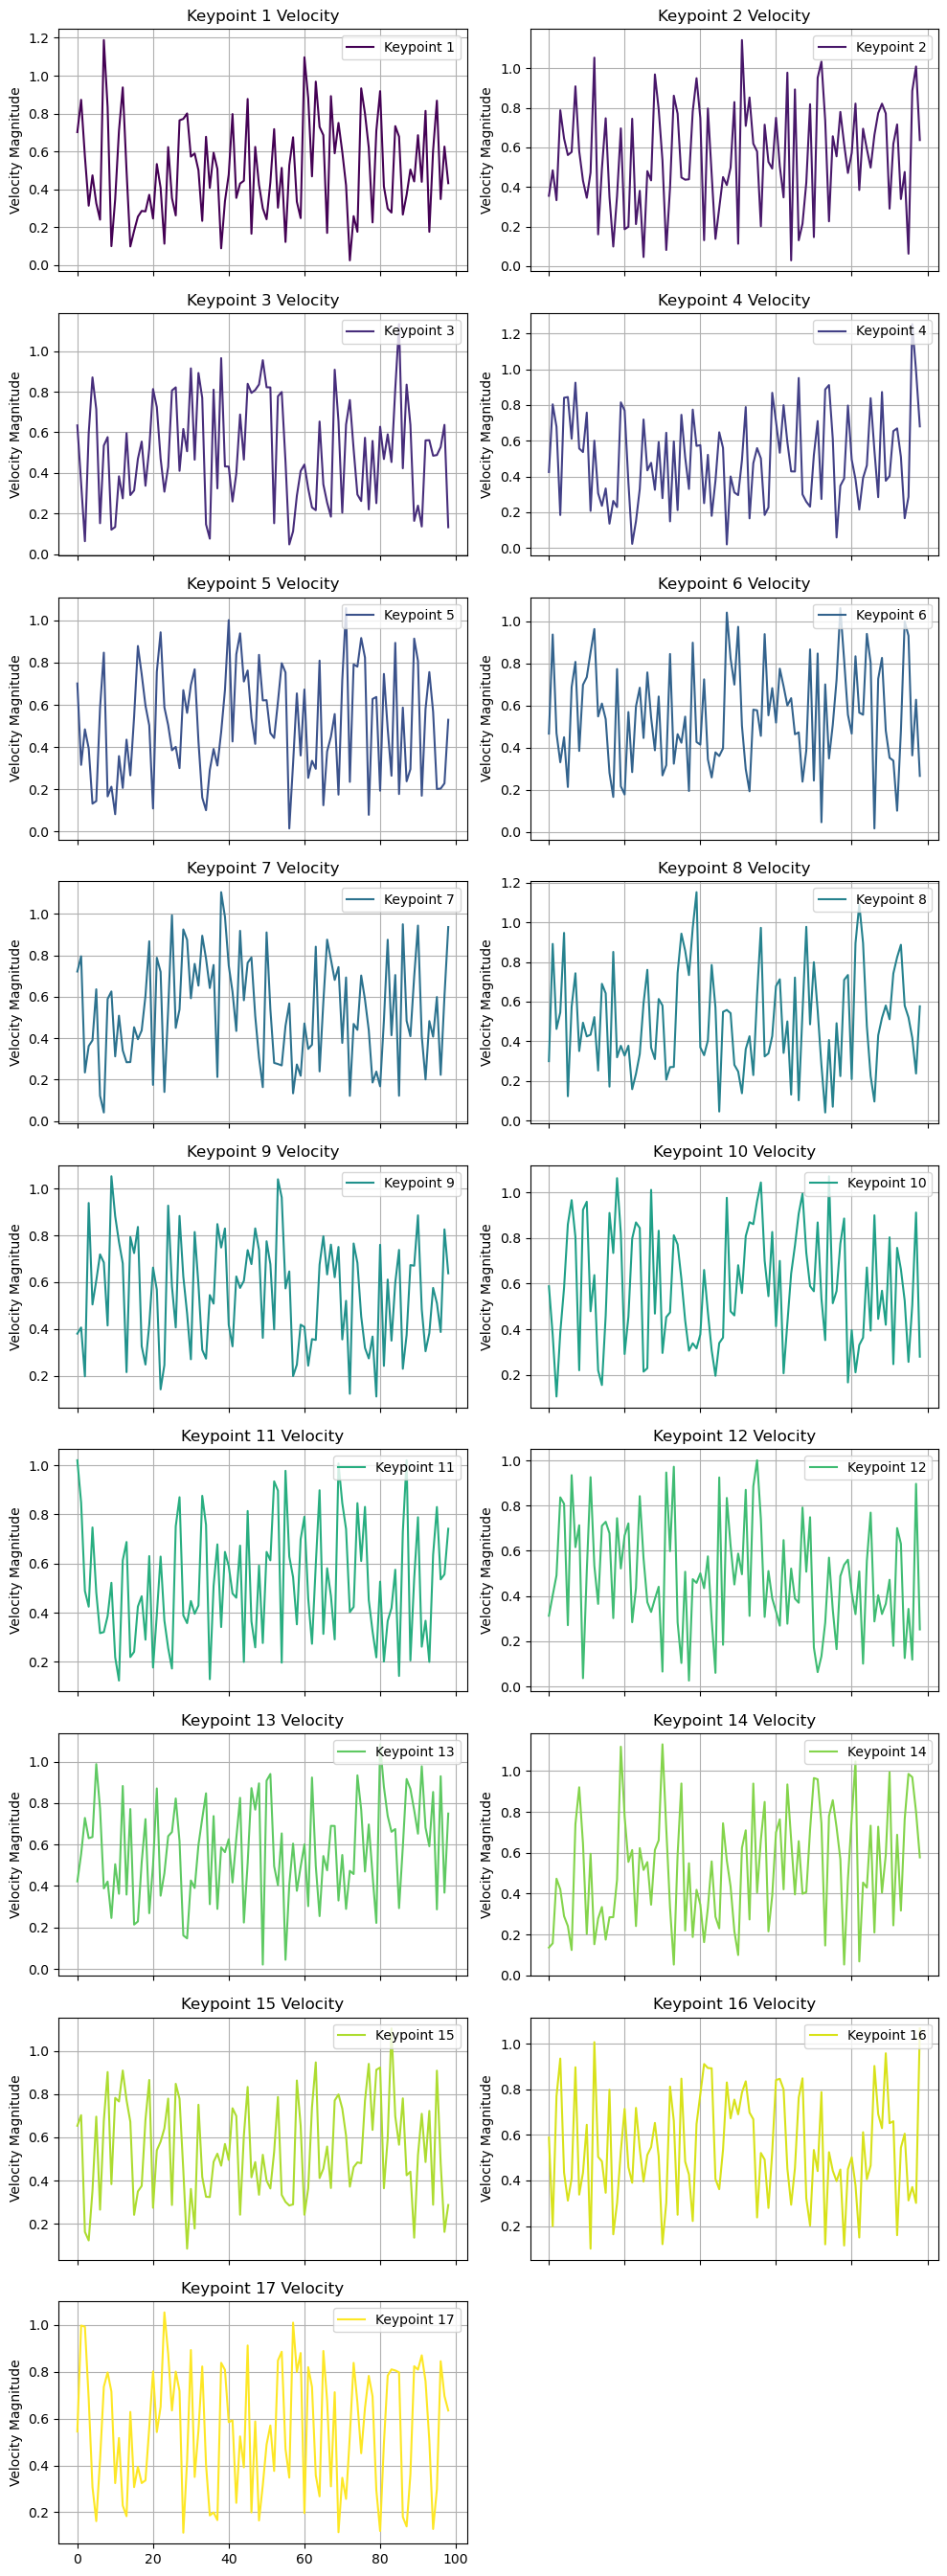

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm


def calculate_velocity(keypoints):
    """
    Calculate the velocity between frames for keypoints data.
    
    Parameters:
        keypoints (numpy.ndarray): Array of shape (N, 17, 3), where N is the number
                                   of frames, 17 is the number of keypoints, and the
                                   last dimension represents (x, y, confidence level).
    
    Returns:
        numpy.ndarray: Array of shape (N-1, 17) containing the velocity magnitude
                       for each keypoint between consecutive frames.
    """
    # Extract the (x, y) coordinates, ignoring the confidence level
    positions = keypoints[:, :, :2]
    
    # Calculate the differences between consecutive frames
    delta_positions = np.diff(positions, axis=0)
    
    # Calculate the velocity magnitude for each keypoint
    velocity = np.linalg.norm(delta_positions, axis=2)
    
    return velocity


def plot_keypoint_velocities(keypoints):
    """
    Plot the velocities of each keypoint over time as subplots.
    
    Parameters:
        keypoints (numpy.ndarray): Array of shape (N, 17, 3), where N is the number
                                   of frames, 17 is the number of keypoints, and the
                                   last dimension represents (x, y, confidence level).
    """
    # Calculate velocities
    velocity = calculate_velocity(keypoints)
    
    # Create subplots for each keypoint in a grid with 2 columns
    num_keypoints = velocity.shape[1]
    cols = 2
    rows = (num_keypoints + 1) // cols  # Calculate required rows for 2 columns
    fig, axs = plt.subplots(rows, cols, figsize=(10, 3 * rows), sharex=True)
    
    # Flatten the axes array for easy iteration
    axs = axs.flatten()
    
    # Use a colormap to vary the colors
    colors = cm.viridis(np.linspace(0, 1, num_keypoints))
    
    for i in range(num_keypoints):
        axs[i].plot(velocity[:, i], color=colors[i], label=f'Keypoint {i+1}')
        axs[i].set_title(f'Keypoint {i+1} Velocity')
        axs[i].set_ylabel('Velocity Magnitude')
        axs[i].grid()
        axs[i].legend(loc='upper right')
    
    # Hide any empty subplots if num_keypoints < rows * cols
    for j in range(num_keypoints, rows * cols):
        axs[j].axis('off')
    
    axs[-1].set_xlabel('Frame')
    plt.tight_layout()
    plt.show()

# Example usage
keypoints = np.random.rand(100, 17, 3)  # Example array with 100 frames
plot_keypoint_velocities(keypoints)


In [4]:

def calculate_velocities(res_array):
    v_array = []

    for i in range(len(res_array) - 1):  # Use -1 to ensure i+1 is within bounds
        v_small = []
        for j in range(len(res_array[0])):

            # Ensure the sub-arrays are not empty
            if len(res_array[i]) == 0 or len(res_array[i + 1]) == 0:
                print(f"Skipping empty sub-array at index {i} or {i + 1}")
                continue

            # Calculate velocity if timestamps are different
            time_diff = res_array[i + 1][j][0] - res_array[i][j][0]
            if time_diff != 0:
                v = (res_array[i + 1][j][1] - res_array[i][j][1]) / time_diff
            else:
                v = 0
            v_small.append(v)
        v_array.append(v_small)

    return np.array(v_array)

In [5]:
import numpy as np
X = df[['keypoints', 'timestamps']]  # Features (keypoints and timestamps)
y = df['label']    
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def flatten_keypoints_with_timestamps(keypoints, timestamps, labels):
    combined_data = []
    
    for kp_list, ts_list, label in zip(keypoints, timestamps, labels):
        # Check if the lengths match
        if len(kp_list) != len(ts_list):
            print(f"Length mismatch in keypoints ({len(kp_list)}) and timestamps ({len(ts_list)}) for label: {label}")
        
        # Even if lengths mismatch, you can decide to process up to the shortest length or handle it differently
        min_length = min(len(kp_list), len(ts_list))
        
        for i in range(min_length):
            # Flatten each keypoint and concatenate it with its timestamp and the label
            combined_data.append(np.concatenate([kp_list[i].flatten(), [ts_list[i]], [label]]))

    return np.array(combined_data)

# Re-run the flattening for training and testing data
X_train_flat = flatten_keypoints_with_timestamps(X_train['keypoints'], X_train['timestamps'], y_train)
X_test_flat = flatten_keypoints_with_timestamps(X_test['keypoints'], X_test['timestamps'], y_test)

# Check the shape of the flattened data
print(f"X_train_flat shape: {X_train_flat.shape}")
print(f"X_test_flat shape: {X_test_flat.shape}")


# Assuming y_train and y_test are your original labels corresponding to your keypoints and timestamps
y_train_binary = (y_train == "house").astype(int)  # Binary encoding for training labels
y_test_binary = (y_test == "house").astype(int)    # Binary encoding for testing labels

# Check lengths to ensure they match
assert len(X_train_flat) == len(y_train_binary), f"Length mismatch: {len(X_train_flat)} vs {len(y_train_binary)}"
assert len(X_test_flat) == len(y_test_binary), f"Length mismatch: {len(X_test_flat)} vs {len(y_test_binary)}"

# Fit the classifier (e.g., SGDClassifier)
from sklearn.linear_model import SGDClassifier

# Initialize the classifier
SGD_clf = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)

# Fit the model
SGD_clf.fit(X_train_flat, y_train_binary)

# Optionally, you can make predictions on the test set
y_pred = SGD_clf.predict(X_test_flat)

# Evaluate the classifier (e.g., accuracy score)
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test_binary, y_pred)
print(f"Accuracy: {accuracy:.2f}")


NameError: name 'train_test_split' is not defined